# Visualise extracted BIOMASS STA stacks

Quick looks of the output of `extract_l1c_roi.py`. For one ROI folder this notebook plots:

1. **Overview**: the footprint of every extracted stack, the ROI and their common area.
2. **One look per stack**: a Pauli RGB of one acquisition per stack, geocoded with `latlon.tif` and drawn on top of the ROI. Pixels outside the common area are dimmed.
3. **All dates of one stack**: HH backscatter for the 7 acquisitions, on the same colour scale.

The images are multilooked for display only. The files on disk stay in full-resolution radar geometry.

### Settings

In [3]:
from pathlib import Path

ROI_DIR = Path("Lac_Tele")    # folder written by extract_l1c_roi.py
PRODUCT = "primary"         # which acquisition per stack: "primary" or a repeat cycle 1-7
LOOKS = (12, 2)             # multilook (azimuth, range) for display, (12, 2) = the LUT grid
DIM_OUTSIDE = 0.35          # brightness of pixels outside the common area
STACK_FOR_DATES = 0         # stack index used in section 3

In [4]:
import json
import warnings

import geopandas as gpd
import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
import numpy as np
import rasterio
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from shapely.geometry import Polygon, box

warnings.filterwarnings("ignore", category=rasterio.errors.NotGeoreferencedWarning)
warnings.filterwarnings("ignore", message="Mean of empty slice")

summary = json.loads((ROI_DIR / "extraction_summary.json").read_text())
roi_bbox = summary["roi"]["bbox"]
roi = box(*roi_bbox)
common = gpd.read_file(ROI_DIR / "common_area.geojson").query("name == 'common_area'").geometry.iloc[0]
stacks = summary["stacks"]

print(f"ROI '{summary['roi']['name']}'  bbox {roi_bbox}")
print(f"Common area: {100 * summary['common_area_fraction_of_roi']:.1f}% of the ROI")
for i, st in enumerate(stacks):
    print(f"  [{i}] {st['folder']}  {len(st['products'])} products")

# every product must be cut with the stack's current window (it changes when the stack selection changes)
stale = []
for st in stacks:
    shape = (st["window"]["height"], st["window"]["width"])
    for p in st["products"]:
        with rasterio.open(ROI_DIR / st["folder"] / p["file"]) as src:
            if src.shape != shape:
                stale.append(f"{st['folder']}/{p['file']}  {src.shape} != window {shape}")
if stale:
    raise RuntimeError("Products cut with an older window, re-run extract_l1c_roi.py for this ROI:\n  "
                       + "\n  ".join(stale))

ROI 'Lac Tele'  bbox [16.98, 0.94, 17.48, 1.44]
Common area: 63.2% of the ROI
  [0] STA3_ascending_20260606-20260624_WRS-33-2  7 products
  [1] STA1_descending_20260916-20261004_WRS-40-154  7 products


### Helpers

In [5]:
# categorical order for stacks (blue, orange, aqua, yellow, magenta, green)
STACK_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
INK = "#2b2b2a"
HALO = [pe.withStroke(linewidth=3.5, foreground=INK)]
# lat/lon axes: keep metres roughly square
ASPECT = 1 / np.cos(np.radians(np.mean(roi_bbox[1::2])))


def multilook(a, looks=LOOKS):
    """Block average, ignoring NaN (no-data)."""
    la, lr = looks
    h, w = a.shape[0] // la * la, a.shape[1] // lr * lr
    return np.nanmean(a[:h, :w].reshape(h // la, la, w // lr, lr), axis=(1, 3))


def pick_product(stack, which=PRODUCT):
    if which == "primary":
        return next(p for p in stack["products"] if p["coregistration_primary"])
    return next(p for p in stack["products"] if int(p["repeat_cycle"]) == int(which))


def load_geometry(stack):
    """Multilooked lat, lon and common-area mask of a stack."""
    folder = ROI_DIR / stack["folder"]
    with rasterio.open(folder / "latlon.tif") as src:
        lat, lon = multilook(src.read(1)), multilook(src.read(2))
    with rasterio.open(folder / "overlap_mask.tif") as src:
        inside = multilook(src.read(1).astype(np.float32)) > 0.5
    return lat, lon, inside


def stretch(db, inside, low=2, high=98):
    """Map dB to 0-1 using percentiles taken inside the common area."""
    lo, hi = np.nanpercentile(db[inside], [low, high])
    return np.clip((db - lo) / (hi - lo), 0, 1)


def pauli_rgba(stack, product, inside):
    """Pauli RGB: R = |HH-VV|^2/2, G = |HV+VH|^2/2, B = |HH+VV|^2/2, as RGBA."""
    with rasterio.open(ROI_DIR / stack["folder"] / product["file"]) as src:
        hh, hv, vh, vv = (src.read(b) for b in range(1, 5))
    channels = [np.abs(hh - vv) ** 2 / 2, np.abs(hv + vh) ** 2 / 2, np.abs(hh + vv) ** 2 / 2]
    del hh, hv, vh, vv
    rgb = np.stack([stretch(10 * np.log10(multilook(c)), inside) for c in channels], axis=-1)
    no_data = np.isnan(rgb).any(axis=-1)
    rgb[~inside] *= DIM_OUTSIDE
    rgba = np.dstack([np.nan_to_num(rgb), (~no_data).astype(float)])
    return rgba


def footprint(lat, lon):
    """Outline of the extracted window, from the border of its lat/lon grid."""
    ring = np.concatenate([
        np.column_stack([lon[0, :], lat[0, :]]),
        np.column_stack([lon[:, -1], lat[:, -1]]),
        np.column_stack([lon[-1, ::-1], lat[-1, ::-1]]),
        np.column_stack([lon[::-1, 0], lat[::-1, 0]]),
    ])
    return Polygon(ring)


def draw_outlines(ax):
    """ROI (dark dashed) and common area (white with a dark halo) on a map axis."""
    ax.plot(*roi.exterior.xy, "--", color=INK, lw=1.2)
    for part in getattr(common, "geoms", [common]):
        ax.plot(*part.exterior.xy, color="white", lw=1.5, path_effects=HALO)


OUTLINE_KEY = [
    Line2D([], [], ls="--", color=INK, lw=1.2, label="ROI"),
    Line2D([], [], color="white", lw=1.5, path_effects=HALO, label="Common area"),
]


def map_axes(ax, pad=0.08, bounds=None):
    w, s, e, n = bounds or roi_bbox
    ax.set_xlim(w - pad, e + pad)
    ax.set_ylim(s - pad, n + pad)
    ax.set_aspect(ASPECT)
    ax.set_xlabel("Longitude (°)")
    ax.set_ylabel("Latitude (°)")
    ax.grid(color="#d9d8d2", lw=0.5)
    ax.set_axisbelow(True)


def stack_title(stack, product):
    swath, orbit = stack["folder"].split("_")[:2]
    date = product["datetime"][:10]
    tag = ", primary" if product["coregistration_primary"] else ""
    return f"{swath} {orbit} · {date} (C{int(product['repeat_cycle']):02d}{tag})"

In [6]:
geometry = [load_geometry(st) for st in stacks]

## 1. Overview: stack footprints, ROI and common area

Each outline is the extracted window of a stack (a rectangle in radar geometry, so a skewed quadrilateral on the map). The grey area is covered by every stack and is where the data is directly comparable.

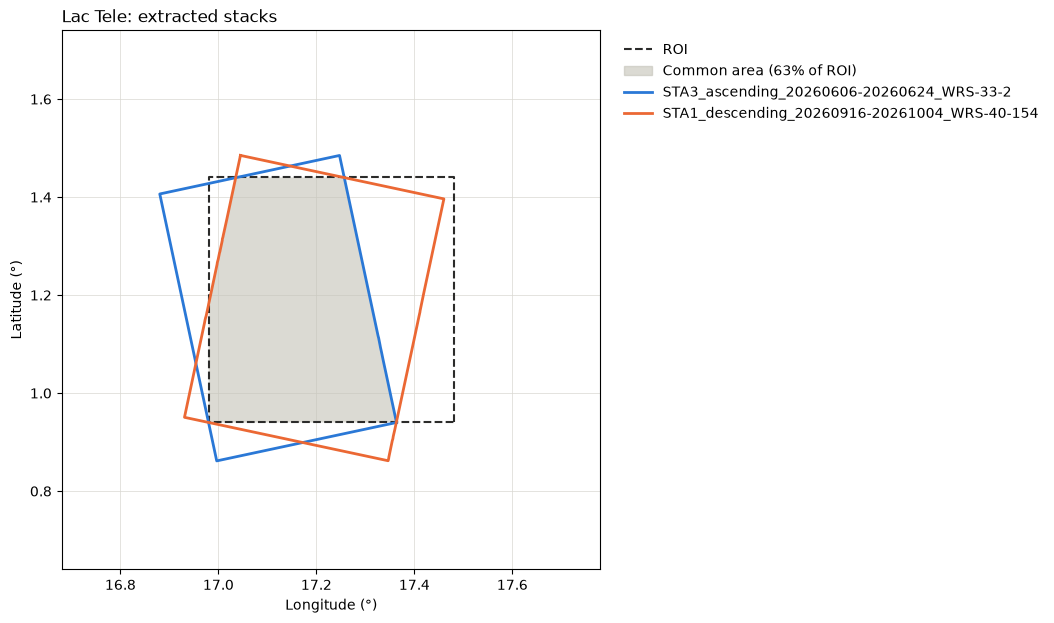

In [7]:
fig, ax = plt.subplots(figsize=(7, 7))
for part in getattr(common, "geoms", [common]):
    ax.fill(*part.exterior.xy, color="#c3c2b7", alpha=0.6, lw=0)
x, y = roi.exterior.xy
ax.plot(x, y, "--", color=INK, lw=1.5)

handles = [
    Line2D([], [], ls="--", color=INK, lw=1.5, label="ROI"),
    Patch(color="#c3c2b7", alpha=0.6, label=f"Common area ({100 * summary['common_area_fraction_of_roi']:.0f}% of ROI)"),
]
for i, (st, (lat, lon, _)) in enumerate(zip(stacks, geometry)):
    color = STACK_COLORS[i % len(STACK_COLORS)]
    ax.plot(*footprint(lat, lon).exterior.xy, color=color, lw=2)
    handles.append(Line2D([], [], color=color, lw=2, label=st["folder"]))

map_axes(ax, pad=0.3)
ax.set_title(f"{summary['roi']['name']}: extracted stacks", loc="left")
ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False)
plt.show()

## 2. One look per stack (Pauli RGB)

Red = |HH−VV|² (double bounce, e.g. flooded forest trunks), green = |HV+VH|² (volume, canopy), blue = |HH+VV|² (surface, open water and bare soil). Each channel is stretched between its 2nd and 98th percentile in dB, measured inside the common area.

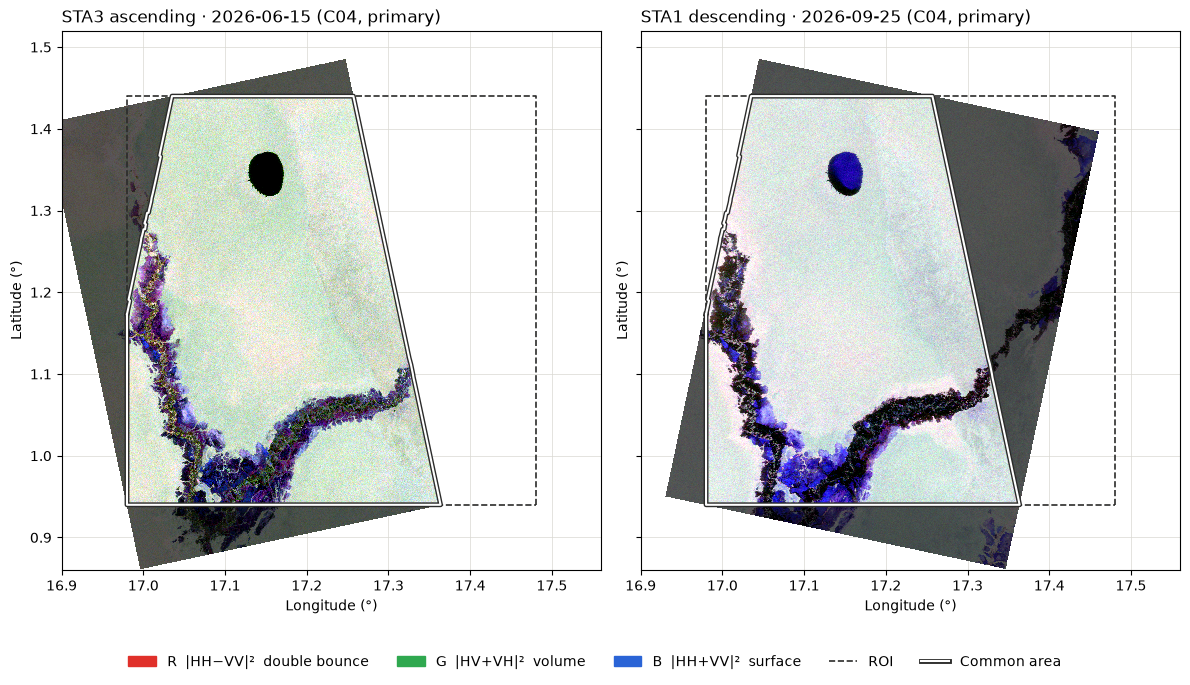

In [8]:
n = len(stacks)
fig, axes = plt.subplots(1, n, figsize=(6 * n, 7), squeeze=False, sharex=True, sharey=True)
for i, (st, (lat, lon, inside)) in enumerate(zip(stacks, geometry)):
    ax = axes[0, i]
    product = pick_product(st)
    rgba = pauli_rgba(st, product, inside)
    ax.pcolormesh(lon, lat, rgba, shading="nearest", rasterized=True)
    draw_outlines(ax)
    map_axes(ax)
    ax.set_title(stack_title(st, product), loc="left")
    del rgba

pauli_key = [Patch(color=c, label=l) for c, l in (
    ("#e0302a", "R  |HH−VV|²  double bounce"),
    ("#2fa84f", "G  |HV+VH|²  volume"),
    ("#2a64d6", "B  |HH+VV|²  surface"),
)] + OUTLINE_KEY
fig.legend(handles=pauli_key, loc="lower center", ncol=5, frameon=False, bbox_to_anchor=(0.5, -0.02))
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

## 3. All dates of one stack (HH backscatter)

The 7 acquisitions of a stack share the same radar grid, so differences between dates are real changes, e.g. flooding under the canopy raises HH through double bounce. Shown on one colour scale, common area only.

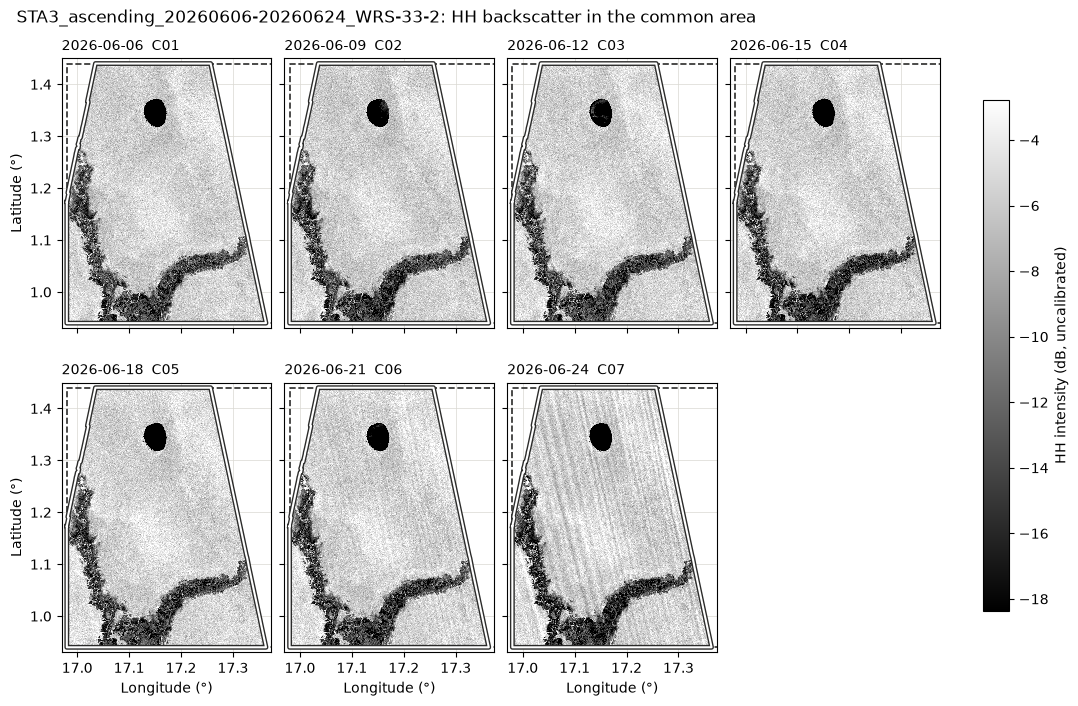

In [9]:
st = stacks[STACK_FOR_DATES]
lat, lon, inside = geometry[STACK_FOR_DATES]

hh_db = []
for product in st["products"]:
    with rasterio.open(ROI_DIR / st["folder"] / product["file"]) as src:
        hh = multilook(np.abs(src.read(1)) ** 2)
    db = 10 * np.log10(hh)
    db[~inside] = np.nan
    hh_db.append(db)
vmin, vmax = np.nanpercentile(np.stack(hh_db), [2, 98])

# zoom on the common area; panel shape follows its extent
bounds = common.bounds
panel_ratio = (bounds[3] - bounds[1]) * ASPECT / (bounds[2] - bounds[0])
cols = 7 if panel_ratio > 1.5 else 4
rows = -(-len(hh_db) // cols)
fig, axes = plt.subplots(rows, cols, figsize=(2.3 * cols + 1.5, 2.3 * panel_ratio * rows + 1),
                         sharex=True, sharey=True, squeeze=False, layout="constrained")
for ax, product, db in zip(axes.flat, st["products"], hh_db):
    mesh = ax.pcolormesh(lon, lat, db, shading="nearest", cmap="gray", vmin=vmin, vmax=vmax, rasterized=True)
    draw_outlines(ax)
    map_axes(ax, pad=0.01, bounds=bounds)
    ax.set_title(f"{product['datetime'][:10]}  C{int(product['repeat_cycle']):02d}", loc="left", fontsize=10)
    ax.label_outer()
for ax in axes.flat[len(hh_db):]:
    ax.set_visible(False)

fig.suptitle(f"{st['folder']}: HH backscatter in the common area", x=0.01, ha="left")
fig.colorbar(mesh, ax=axes, shrink=0.8, label="HH intensity (dB, uncalibrated)")
plt.show()

### Mean HH and HV in the common area through time

One line per stack and polarisation, on a single dB axis.

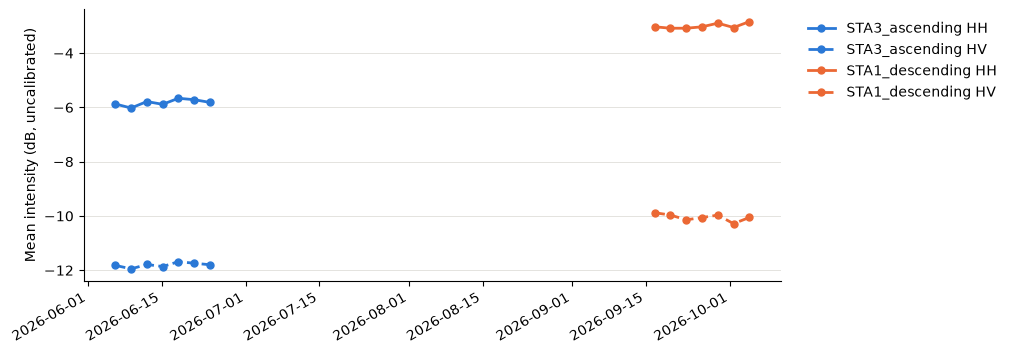

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
for i, st_i in enumerate(stacks):
    _, _, inside_i = geometry[i]
    color = STACK_COLORS[i % len(STACK_COLORS)]
    for band, pol, style in ((1, "HH", "-"), (2, "HV", "--")):
        dates, values = [], []
        for product in st_i["products"]:
            with rasterio.open(ROI_DIR / st_i["folder"] / product["file"]) as src:
                power = multilook(np.abs(src.read(band)) ** 2)
            dates.append(np.datetime64(product["datetime"][:19]))
            values.append(10 * np.log10(np.nanmean(power[inside_i])))
        ax.plot(dates, values, style, color=color, lw=2, marker="o", ms=5, label=f"{st_i['folder'].split('_2')[0]} {pol}")

ax.set_ylabel("Mean intensity (dB, uncalibrated)")
ax.grid(axis="y", color="#d9d8d2", lw=0.5)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False)
fig.autofmt_xdate()
plt.show()